# Fulfilment Pulse: Data Exploration

This notebook explores public Bureau of Meteorology observations alongside a small, fully synthetic Melbourne order sample. It checks data shape, quality, distributions, and date-level overlap. The order sample covers only six days, so findings are descriptive examples, not evidence of real retail behaviour or weather effects.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

DATA_DIR = Path.cwd() / "Data"
print(f"Using data directory: {DATA_DIR}")

Using data directory: c:\Users\dinil\OneDrive\Documents\GitHub\Fulfillment-Pulsa\Data


In [2]:
station_dtype = {"Bureau of Meteorology station number": "string"}
temperature = pd.read_csv(
    DATA_DIR / "Temperature_Data.csv",
    dtype=station_dtype,
)
rainfall = pd.read_csv(
    DATA_DIR / "rainfall_Data.csv",
    dtype=station_dtype,
)

print("temperature shape:", temperature.shape)
print("temperature columns:", list(temperature.columns))
print("rainfall shape:", rainfall.shape)
print("rainfall columns:", list(rainfall.columns))

temperature shape: (5001, 8)
temperature columns: ['Product code', 'Bureau of Meteorology station number', 'Year', 'Month', 'Day', 'Maximum temperature (Degree C)', 'Days of accumulation of maximum temperature', 'Quality']
rainfall shape: (254, 8)
rainfall columns: ['Product code', 'Bureau of Meteorology station number', 'Year', 'Month', 'Day', 'Rainfall amount (millimetres)', 'Period over which rainfall was measured (days)', 'Quality']


In [3]:
temperature.head()

,Product code,Bureau of Meteorology station number,Year,Month,Day,Maximum temperature (Degree C),Days of accumulation of maximum temperature,Quality
0,IDCJAC0010,086338,2013,1,1,NaN,NaN,NaN
1,IDCJAC0010,086338,2013,1,2,NaN,NaN,NaN
2,IDCJAC0010,086338,2013,1,3,NaN,NaN,NaN
3,IDCJAC0010,086338,2013,1,4,NaN,NaN,NaN
4,IDCJAC0010,086338,2013,1,5,NaN,NaN,NaN


## Temperature observations

The temperature file contains daily maximums in degrees Celsius from station `086338`. Treat blank values as missing, not zero. The station is a broad local proxy; it is not a measurement for every delivery zone.

In [4]:
print("Missing values by column:")
print(temperature.isna().sum())
print("Total missing values:", temperature.isna().sum().sum())

Missing values by column:
Product code                                     0
Bureau of Meteorology station number             0
Year                                             0
Month                                            0
Day                                              0
Maximum temperature (Degree C)                 155
Days of accumulation of maximum temperature    155
Quality                                        156
dtype: int64
Total missing values: 466


In [5]:
temperature['Maximum temperature (Degree C)'].describe()

count    4846.000000
mean       20.350929
std         6.020962
min         9.000000
25%        15.800000
50%        19.100000
75%        23.600000
max        43.500000
Name: Maximum temperature (Degree C), dtype: float64

In [6]:
temperature["date"] = pd.to_datetime(temperature[["Year", "Month", "Day"]])


In [7]:
temperature.duplicated().sum()

np.int64(0)

In [8]:
temp_column = "Maximum temperature (Degree C)"
condition_one = temperature[temp_column] > 30
condition_two = temperature["date"].dt.year >= 2020

temperature.loc[condition_one & condition_two, ["date", temp_column]]

,date,Maximum temperature (Degree C)
2558,2020-01-03,36.6
2564,2020-01-09,31.9
2565,2020-01-10,32.9
2568,2020-01-13,32.2
2569,2020-01-14,33.8
...,...,...
4798,2026-02-20,30.8
4805,2026-02-27,31.0
4806,2026-02-28,30.5
4807,2026-03-01,30.7


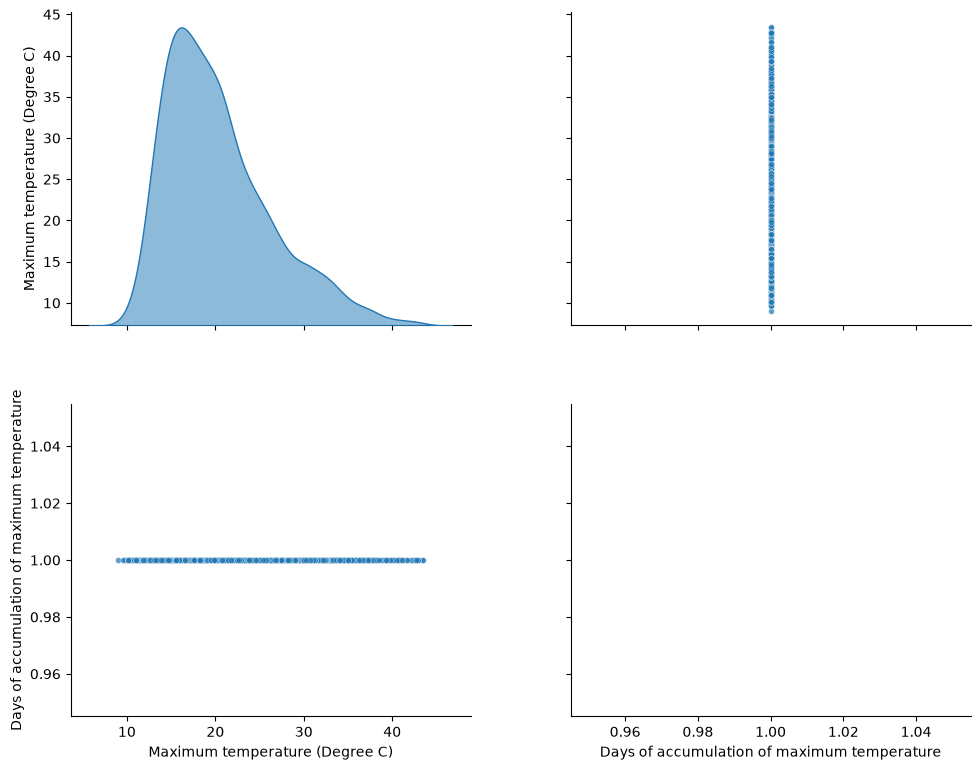

In [9]:
temp_vars = [
    "Maximum temperature (Degree C)",
    "Days of accumulation of maximum temperature",
]

pairplot_df = temperature[temp_vars].dropna()

g = sns.pairplot(
    pairplot_df,
    diag_kind="kde",
    height=2.4,
    aspect=1.1,
    plot_kws={"s": 18, "alpha": 0.7},
    diag_kws={"fill": True, "alpha": 0.5},
)

g.fig.set_size_inches(10, 8)
g.fig.subplots_adjust(
    left=0.08,
    right=0.98,
    bottom=0.08,
    top=0.96,
    wspace=0.25,
    hspace=0.25,
)

plt.show()


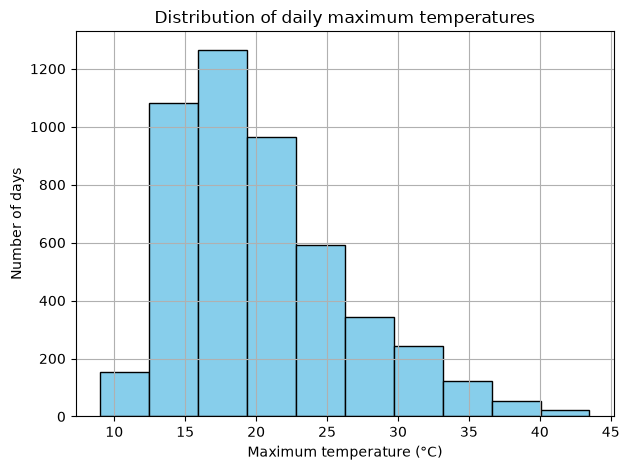

In [10]:
temperature_column = "Maximum temperature (Degree C)"
ax = temperature[temperature_column].hist(
    bins=10,
    color="skyblue",
    edgecolor="black",
)
ax.set_title("Distribution of daily maximum temperatures")
ax.set_xlabel("Maximum temperature (°C)")
ax.set_ylabel("Number of days")
plt.tight_layout()
plt.show()

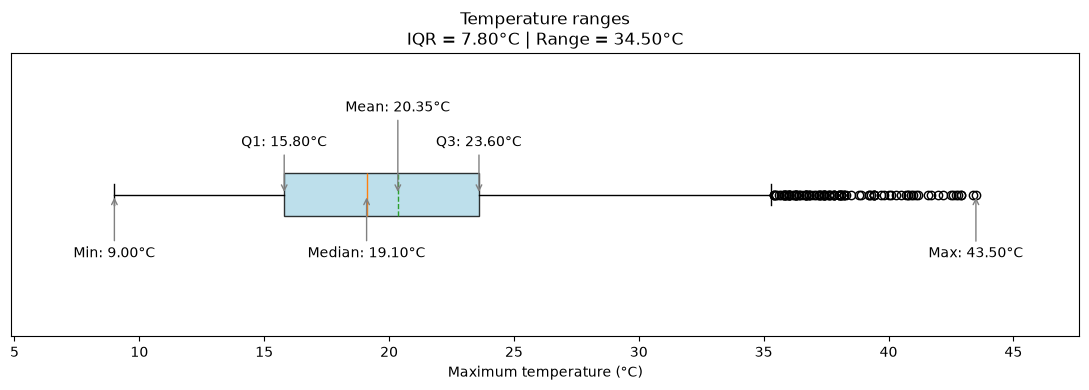

In [11]:
temps = temperature["Maximum temperature (Degree C)"].dropna()

minimum = temps.min()
maximum = temps.max()
median = temps.median()
mean = temps.mean()
q1 = temps.quantile(0.25)
q3 = temps.quantile(0.75)
IQR = q3 - q1

fig, ax = plt.subplots(figsize=(11, 4))

ax.boxplot(
    temps,
    showmeans=True,
    orientation="horizontal",
    meanline=True,
    patch_artist=True,
    boxprops=dict(facecolor="lightblue", alpha=0.8),
)

labels = [
    ("Min", minimum, -45),
    ("Q1", q1, 35),
    ("Median", median, -45),
    ("Mean", mean, 60),
    ("Q3", q3, 35),
    ("Max", maximum, -45),
]

for label, value, offset in labels:
    ax.annotate(
        f"{label}: {value:.2f}°C",
        xy=(value, 1),
        xytext=(0, offset),
        textcoords="offset points",
        ha="center",
        arrowprops=dict(arrowstyle="->", color="gray")
    )

ax.set_title(
    f"Temperature ranges\n"
    f"IQR = {IQR:.2f}°C | Range = {maximum - minimum:.2f}°C"
)
ax.set_xlabel("Maximum temperature (°C)")
ax.set_yticks([])
ax.margins(x=0.12)

plt.tight_layout()
plt.show()

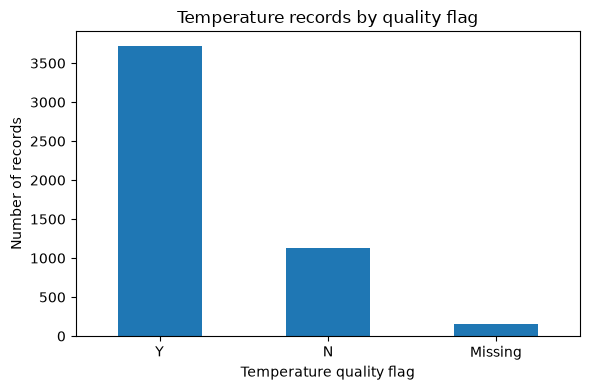

In [12]:
temperature_quality = temperature["Quality"].fillna("Missing").value_counts()

ax = temperature_quality.plot(kind="bar", figsize=(6, 4), color="tab:blue")
ax.set_xlabel("Temperature quality flag")
ax.set_ylabel("Number of records")
ax.set_title("Temperature records by quality flag")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

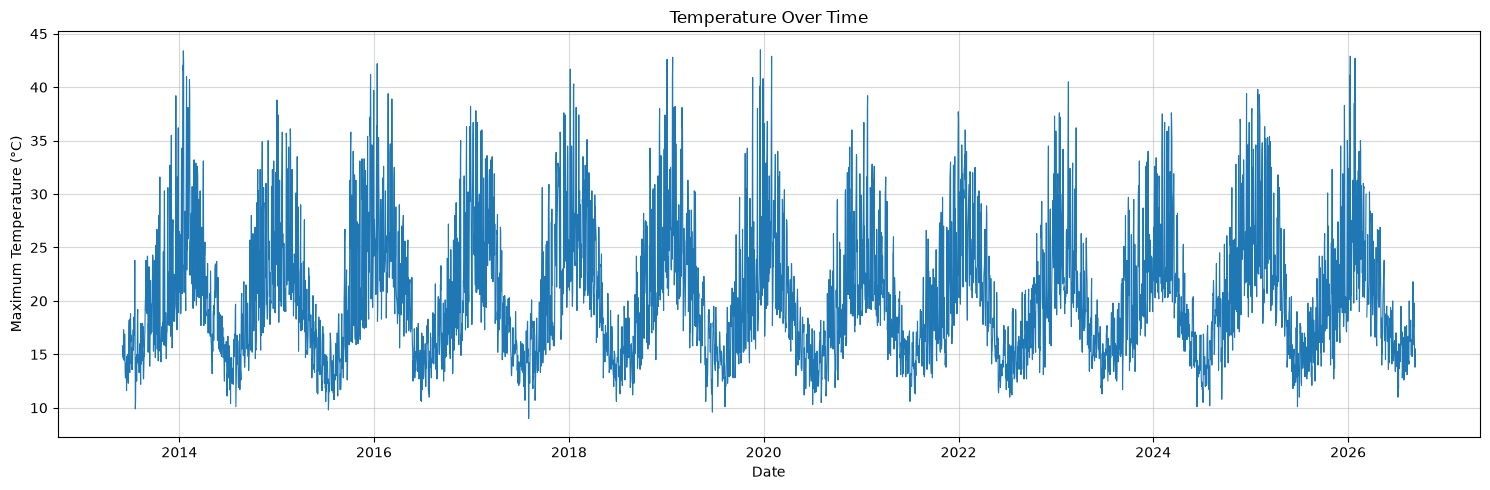

In [13]:
temperature = temperature.copy()
temperature["date"] = pd.to_datetime(temperature["date"])
temperature = temperature.sort_values("date").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(
    temperature["date"],
    temperature["Maximum temperature (Degree C)"],
    linewidth=0.8,
    color="tab:blue",
)
ax.set_xlabel("Date")
ax.set_ylabel("Maximum Temperature (°C)")
ax.set_title("Temperature Over Time")
ax.grid(True, alpha=0.5)
plt.tight_layout()
plt.show()

In [14]:
temperature.info()

<class 'pandas.DataFrame'>
RangeIndex: 5001 entries, 0 to 5000
Data columns (total 9 columns):
 #   Column                                       Non-Null Count  Dtype         
---  ------                                       --------------  -----         
 0   Product code                                 5001 non-null   str           
 1   Bureau of Meteorology station number         5001 non-null   string        
 2   Year                                         5001 non-null   int64         
 3   Month                                        5001 non-null   int64         
 4   Day                                          5001 non-null   int64         
 5   Maximum temperature (Degree C)               4846 non-null   float64       
 6   Days of accumulation of maximum temperature  4846 non-null   float64       
 7   Quality                                      4845 non-null   str           
 8   date                                         5001 non-null   datetime64[us]
dtypes: dateti

## Rainfall observations

The rainfall file contains daily totals in millimetres from station `086232`, a different station from the temperature file. Confirm station metadata before describing these measures as a single-location weather record.

In [15]:
rainfall.isnull().sum()

Product code                                        0
Bureau of Meteorology station number                0
Year                                                0
Month                                               0
Day                                                 0
Rainfall amount (millimetres)                       0
Period over which rainfall was measured (days)    152
Quality                                             0
dtype: int64

In [16]:
rainfall.describe()

,Year,Month,Day,Rainfall amount (millimetres),Period over which rainfall was measured (days)
count,254.0,254.000000,254.000000,254.000000,102.0
mean,2026.0,4.720472,15.283465,1.461811,1.0
std,0.0,2.427733,8.864280,3.536137,0.0
min,2026.0,1.000000,1.000000,0.000000,1.0
25%,2026.0,3.000000,8.000000,0.000000,1.0
50%,2026.0,5.000000,15.000000,0.000000,1.0
75%,2026.0,7.000000,23.000000,1.000000,1.0
max,2026.0,9.000000,31.000000,25.000000,1.0


In [17]:
rainfall["date"] = pd.to_datetime(rainfall[["Year", "Month", "Day"]])

In [18]:
rainfall.duplicated().sum()

np.int64(0)

In [19]:
rain_column = "Rainfall amount (millimetres)"

rainfall.loc[
    rainfall[rain_column].idxmax(),
    ["date", rain_column]
]

date                             2026-08-10 00:00:00
Rainfall amount (millimetres)                   25.0
Name: 221, dtype: object

In [20]:
rain_column = "Rainfall amount (millimetres)"

rainfall.loc[
    rainfall[rain_column].idxmin(),
    ["date", rain_column]
]

date                             2026-01-01 00:00:00
Rainfall amount (millimetres)                    0.0
Name: 0, dtype: object

In [21]:
rainy_days = rainfall[
    rainfall["Rainfall amount (millimetres)"] > 0
].copy()

rainy_days

,Product code,Bureau of Meteorology station number,Year,Month,Day,Rainfall amount (millimetres),Period over which rainfall was measured (days),Quality,date
9,IDCJAC0009,086232,2026,1,10,0.3,1.0,Y,2026-01-10
21,IDCJAC0009,086232,2026,1,22,0.6,1.0,Y,2026-01-22
31,IDCJAC0009,086232,2026,2,1,1.7,1.0,N,2026-02-01
39,IDCJAC0009,086232,2026,2,9,1.4,1.0,N,2026-02-09
42,IDCJAC0009,086232,2026,2,12,11.2,1.0,N,2026-02-12
...,...,...,...,...,...,...,...,...,...
240,IDCJAC0009,086232,2026,8,29,1.7,1.0,N,2026-08-29
246,IDCJAC0009,086232,2026,9,4,2.8,1.0,N,2026-09-04
247,IDCJAC0009,086232,2026,9,5,7.6,1.0,N,2026-09-05
248,IDCJAC0009,086232,2026,9,6,0.8,1.0,N,2026-09-06


In [22]:
rain_values = rainfall[rain_column].dropna()
wet_day_count = int(rain_values.gt(0).sum())
zero_rain_day_count = int(rain_values.eq(0).sum())
observed_day_count = len(rain_values)

print(f"Days with a recorded rainfall value: {observed_day_count}")
print(f"Wet days (> 0 mm): {wet_day_count}")
print(f"Zero-rain days: {zero_rain_day_count} ({zero_rain_day_count / observed_day_count:.1%})")
print(f"Total recorded rainfall: {rain_values.sum():.1f} mm")

Days with a recorded rainfall value: 254
Wet days (> 0 mm): 102
Zero-rain days: 152 (59.8%)
Total recorded rainfall: 371.3 mm


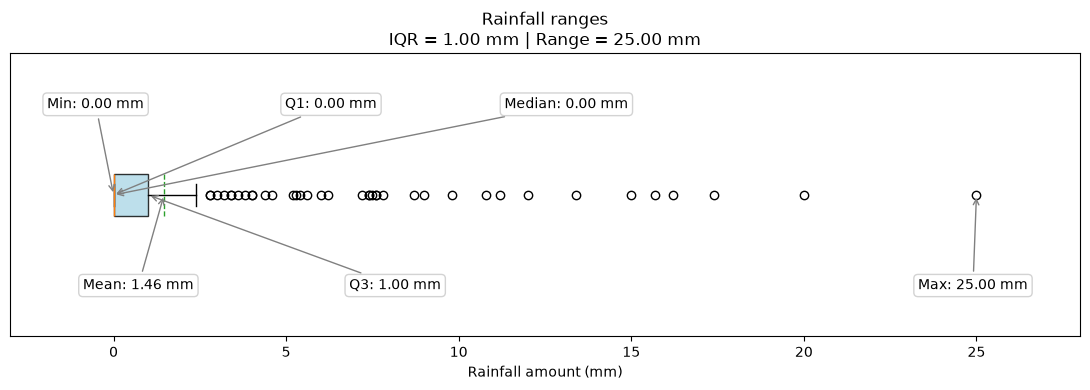

In [23]:
rain = rainfall["Rainfall amount (millimetres)"].dropna()

minimum = rain.min()
maximum = rain.max()
median = rain.median()
mean = rain.mean()
q1 = rain.quantile(0.25)
q3 = rain.quantile(0.75)
IQR = q3 - q1

fig, ax = plt.subplots(figsize=(11, 4))

ax.boxplot(
    rain,
    showmeans=True,
    orientation="horizontal",
    meanline=True,
    patch_artist=True,
    boxprops=dict(facecolor="lightblue", alpha=0.8),
)

labels = [
    ("Min", minimum, (0.08, 0.82)),
    ("Q1", q1, (0.30, 0.82)),
    ("Median", median, (0.52, 0.82)),
    ("Mean", mean, (0.12, 0.18)),
    ("Q3", q3, (0.36, 0.18)),
    ("Max", maximum, (0.90, 0.18)),
]

for label, value, position in labels:
    ax.annotate(
        f"{label}: {value:.2f} mm",
        xy=(value, 1),
        xytext=position,
        textcoords="axes fraction",
        ha="center",
        va="center",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="lightgray"),
        arrowprops=dict(arrowstyle="->", color="gray"),
    )

ax.set_title(
    f"Rainfall ranges\n"
    f"IQR = {IQR:.2f} mm | Range = {maximum - minimum:.2f} mm"
)
ax.set_xlabel("Rainfall amount (mm)")
ax.set_yticks([])
ax.margins(x=0.12)

plt.tight_layout()
plt.show()

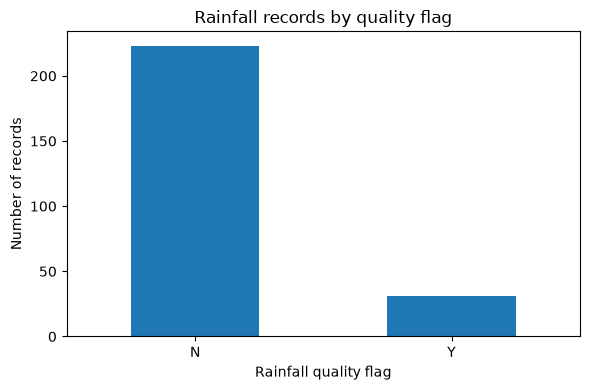

In [24]:
rainfall_quality = rainfall["Quality"].fillna("Missing").value_counts()

ax = rainfall_quality.plot(kind="bar", figsize=(6, 4), color="tab:blue")
ax.set_xlabel("Rainfall quality flag")
ax.set_ylabel("Number of records")
ax.set_title("Rainfall records by quality flag")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

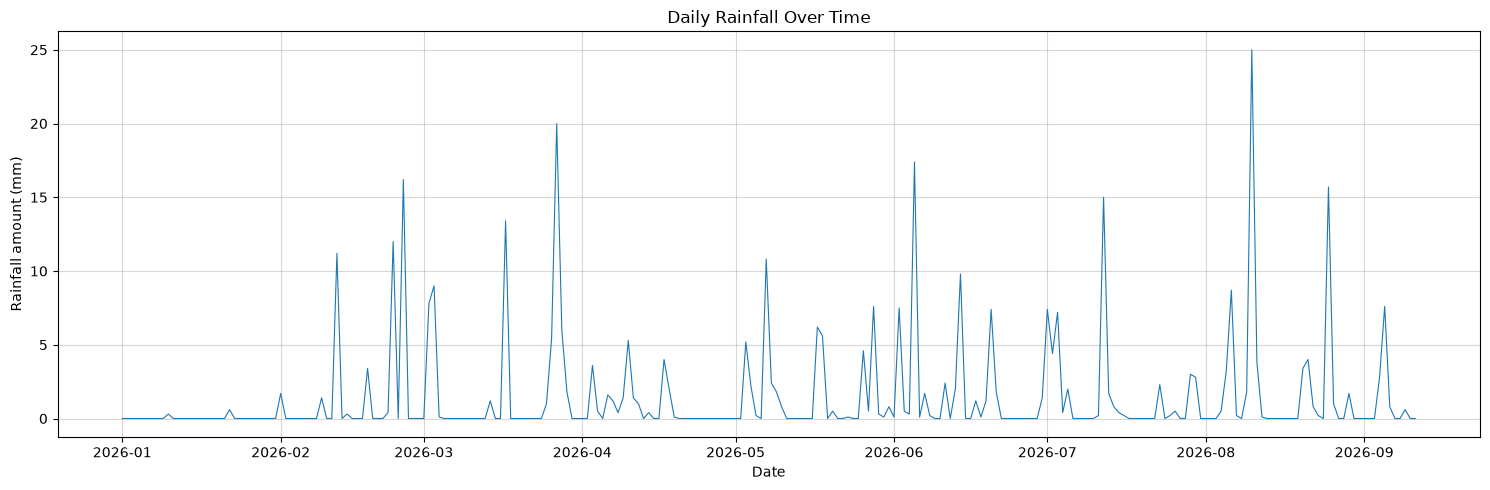

In [25]:
rainfall = rainfall.copy()
rainfall["date"] = pd.to_datetime(rainfall["date"])
rainfall = rainfall.sort_values("date").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(
    rainfall["date"],
    rainfall["Rainfall amount (millimetres)"],
    linewidth=0.8,
    color="tab:blue",
)
ax.set_xlabel("Date")
ax.set_ylabel("Rainfall amount (mm)")
ax.set_title("Daily Rainfall Over Time")
ax.grid(True, alpha=0.5)
plt.tight_layout()
plt.show()

## Synthetic order sample

All order fields, including the delay flag and fulfilment stage, are simulated. Timestamps are interpreted as Melbourne local time; there is no timezone offset in the CSV. The current sample contains only 30 orders across six dates.

In [26]:
order = pd.read_csv(DATA_DIR / "fictitious_orders_melbourne.csv")
order["order_timestamp"] = pd.to_datetime(order["order_timestamp"], errors="coerce")
display(order.head())

,order_id,order_timestamp,delivery_zone,item_count,promised_window,fulfilment_stage,basket_category,simulated_delay_flag,is_synthetic
0,ORD-20260101-001,2026-01-01 08:10:00,Melbourne CBD,3,08:00-10:00,packed,groceries,False,True
1,ORD-20260101-002,2026-01-01 09:45:00,Inner North,5,09:00-11:00,picked,household,False,True
2,ORD-20260101-003,2026-01-01 12:15:00,South East Melbourne,2,12:00-14:00,packed,essentials,False,True
3,ORD-20260101-004,2026-01-01 18:20:00,Western Suburbs,4,18:00-20:00,packed,groceries,False,True
4,ORD-20260101-005,2026-01-01 20:05:00,Eastern Suburbs,6,19:30-21:30,dispatched,meal-kit,False,True


In [27]:
order["order_timestamp"] = pd.to_datetime(order["order_timestamp"])

In [28]:
order["item_count"].describe()

count    30.000000
mean      4.433333
std       2.028815
min       2.000000
25%       3.000000
50%       4.000000
75%       6.000000
max       9.000000
Name: item_count, dtype: float64

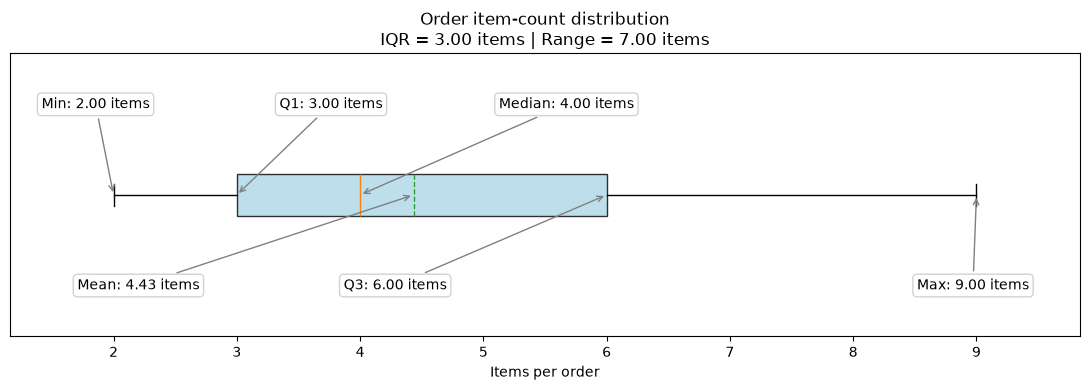

In [29]:
item_counts = order["item_count"].dropna()

minimum = item_counts.min()
maximum = item_counts.max()
median = item_counts.median()
mean = item_counts.mean()
q1 = item_counts.quantile(0.25)
q3 = item_counts.quantile(0.75)
IQR = q3 - q1

fig, ax = plt.subplots(figsize=(11, 4))
ax.boxplot(
    item_counts,
    showmeans=True,
    orientation="horizontal",
    meanline=True,
    patch_artist=True,
    boxprops=dict(facecolor="lightblue", alpha=0.8),
)

labels = [
    ("Min", minimum, (0.08, 0.82)),
    ("Q1", q1, (0.30, 0.82)),
    ("Median", median, (0.52, 0.82)),
    ("Mean", mean, (0.12, 0.18)),
    ("Q3", q3, (0.36, 0.18)),
    ("Max", maximum, (0.90, 0.18)),
]

for label, value, position in labels:
    ax.annotate(
        f"{label}: {value:.2f} items",
        xy=(value, 1),
        xytext=position,
        textcoords="axes fraction",
        ha="center",
        va="center",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="lightgray"),
        arrowprops=dict(arrowstyle="->", color="gray"),
    )

ax.set_title(
    f"Order item-count distribution\n"
    f"IQR = {IQR:.2f} items | Range = {maximum - minimum:.2f} items"
)
ax.set_xlabel("Items per order")
ax.set_yticks([])
ax.margins(x=0.12)
plt.tight_layout()
plt.show()

In [30]:
item_counts = order["item_count"].dropna()
q1 = item_counts.quantile(0.25)
q3 = item_counts.quantile(0.75)
IQR = q3 - q1
lower_bound = q1 - 1.5 * IQR
upper_bound = q3 + 1.5 * IQR

outliers = order.loc[
    (order["item_count"] < lower_bound) | (order["item_count"] > upper_bound),
    ["order_id", "item_count"],
]

print(f"Outlier bounds: {lower_bound:.2f} to {upper_bound:.2f} items")
display(outliers)

Outlier bounds: -1.50 to 10.50 items


,order_id,item_count


In [31]:
order.shape

(30, 9)

In [32]:
order.info()

<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   order_id              30 non-null     str           
 1   order_timestamp       30 non-null     datetime64[us]
 2   delivery_zone         30 non-null     str           
 3   item_count            30 non-null     int64         
 4   promised_window       30 non-null     str           
 5   fulfilment_stage      30 non-null     str           
 6   basket_category       30 non-null     str           
 7   simulated_delay_flag  30 non-null     bool          
 8   is_synthetic          30 non-null     bool          
dtypes: bool(2), datetime64[us](1), int64(1), str(5)
memory usage: 1.8 KB


In [33]:
order.isna().sum()

order_id                0
order_timestamp         0
delivery_zone           0
item_count              0
promised_window         0
fulfilment_stage        0
basket_category         0
simulated_delay_flag    0
is_synthetic            0
dtype: int64

### Order quality checks

Check the synthetic sample for missing fields, duplicate IDs, invalid timestamps, non-positive or fractional item counts, and records not labelled synthetic. These checks describe this input sample; they do not replace Silver-layer quarantine rules in a production pipeline.

In [34]:
missing_by_column = order.isna().sum()
assert missing_by_column.sum() == 0, "Order data contains missing values"
assert order["order_id"].is_unique, "Order IDs must be unique"
assert order["order_timestamp"].notna().all(), "Order timestamps must parse successfully"
assert pd.api.types.is_numeric_dtype(order["item_count"]), "Item counts must be numeric"
assert order["item_count"].gt(0).all(), "Item counts must be positive"
assert order["item_count"].mod(1).eq(0).all(), "Item counts must be whole numbers"
assert order["is_synthetic"].astype("string").str.upper().eq("TRUE").all(), "Every order must be labelled synthetic"

print(f"Rows: {len(order)} | Unique order IDs: {order['order_id'].nunique()}")
print(f"Date range: {order['order_timestamp'].min()} to {order['order_timestamp'].max()}")
print("Missing values by column:")
display(missing_by_column.to_frame("missing_count"))

Rows: 30 | Unique order IDs: 30
Date range: 2026-01-01 08:10:00 to 2026-01-06 21:15:00
Missing values by column:


,missing_count
order_id,0
order_timestamp,0
delivery_zone,0
item_count,0
promised_window,0
fulfilment_stage,0
basket_category,0
simulated_delay_flag,0
is_synthetic,0


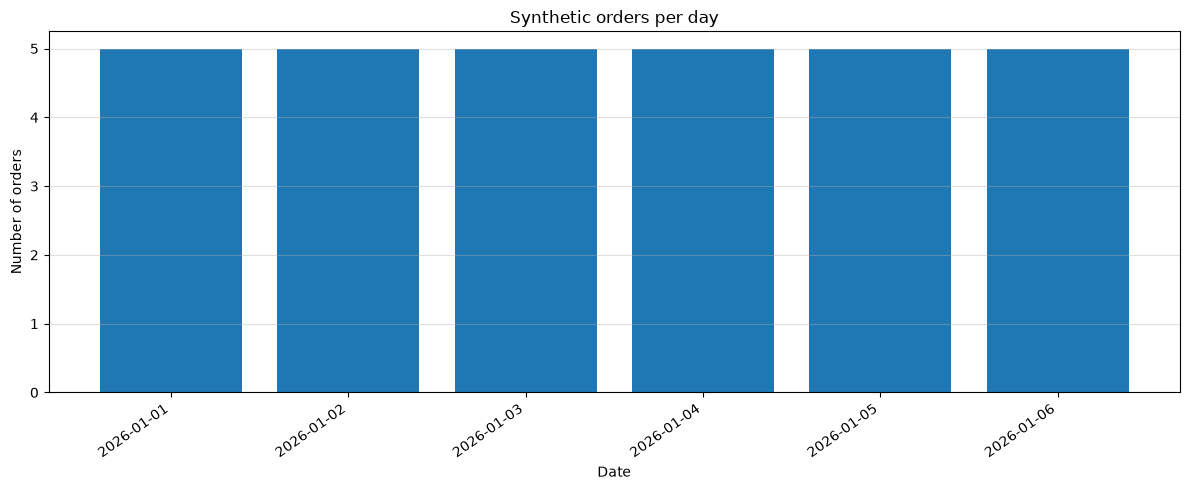

In [35]:
daily_order_counts = order.set_index("order_timestamp").resample("D").size()

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(daily_order_counts.index, daily_order_counts.values, color="tab:blue")
ax.set_xlabel("Date")
ax.set_ylabel("Number of orders")
ax.set_title("Synthetic orders per day")
ax.grid(axis="y", alpha=0.4)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

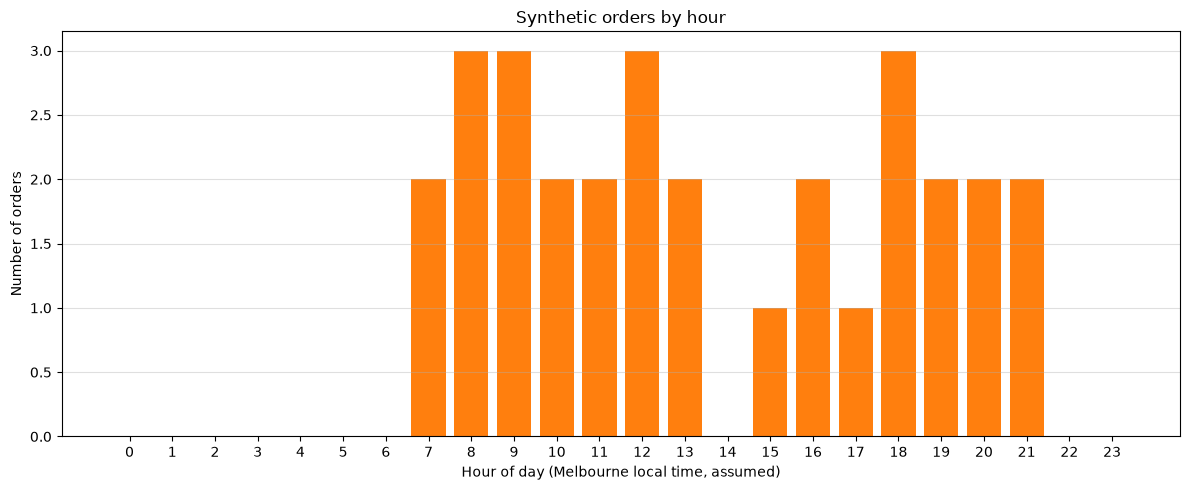

In [36]:
orders_by_hour = order["order_timestamp"].dt.hour.value_counts().reindex(range(24), fill_value=0)

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(orders_by_hour.index, orders_by_hour.values, color="tab:orange")
ax.set_xlabel("Hour of day (Melbourne local time, assumed)")
ax.set_ylabel("Number of orders")
ax.set_title("Synthetic orders by hour")
ax.set_xticks(range(24))
ax.grid(axis="y", alpha=0.4)
plt.tight_layout()
plt.show()

delivery_zone
Melbourne CBD           31
South East Melbourne    24
Western Suburbs         23
Eastern Suburbs         23
Inner North             18
Northern Suburbs        14
Name: total_items, dtype: int64

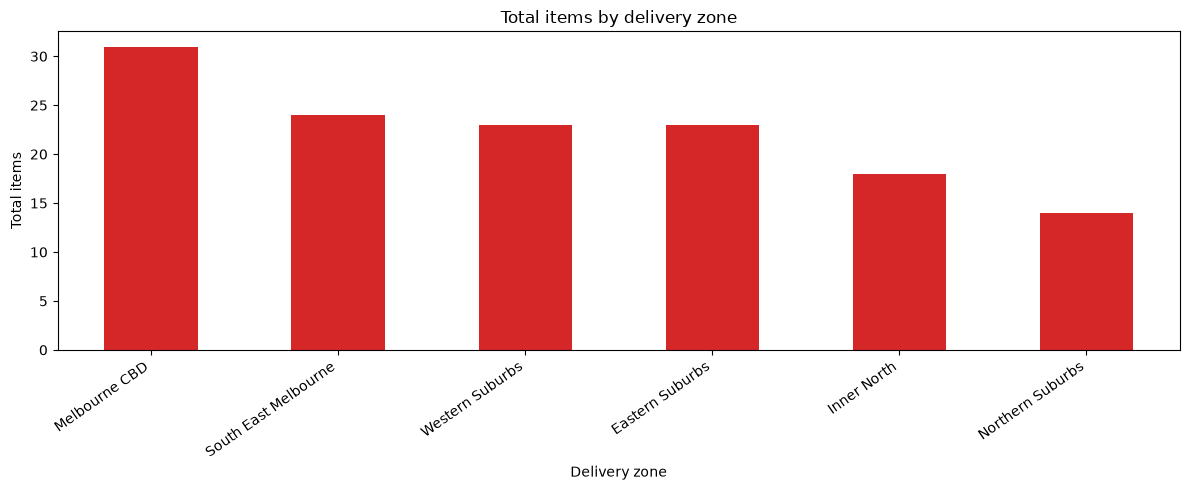

In [37]:
items_by_zone = order.groupby("delivery_zone")["item_count"].sum().sort_values(ascending=False)

display(items_by_zone.rename("total_items"))
ax = items_by_zone.plot(kind="bar", figsize=(12, 5), color="tab:red")
ax.set_xlabel("Delivery zone")
ax.set_ylabel("Total items")
ax.set_title("Total items by delivery zone")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

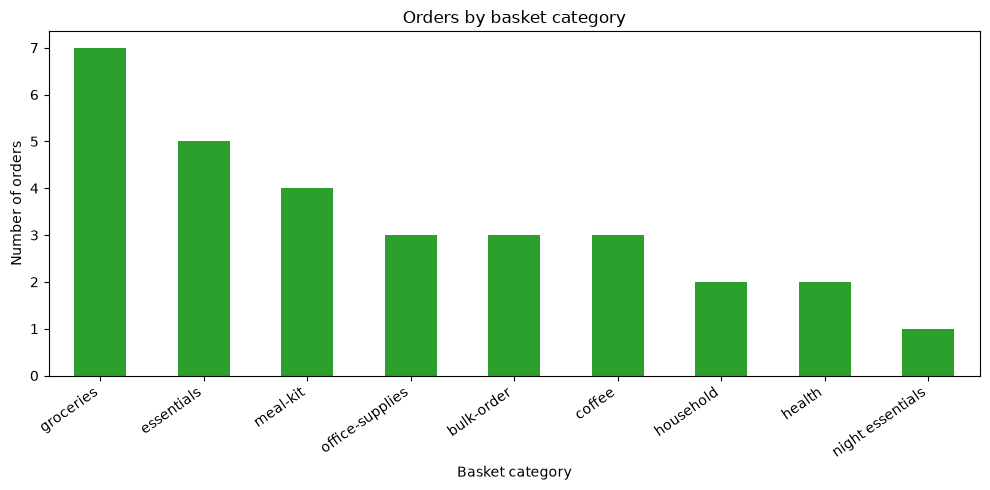

In [38]:
basket_counts = order["basket_category"].value_counts()

ax = basket_counts.plot(kind="bar", figsize=(10, 5), color="tab:green")
ax.set_xlabel("Basket category")
ax.set_ylabel("Number of orders")
ax.set_title("Orders by basket category")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

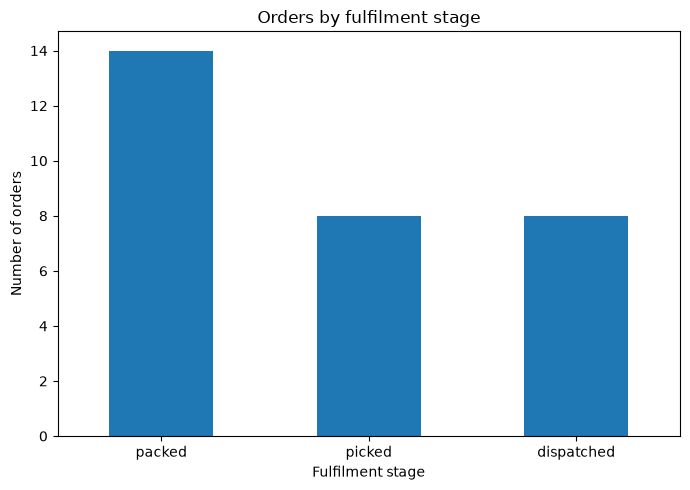

In [39]:
fulfilment_counts = order["fulfilment_stage"].value_counts()

ax = fulfilment_counts.plot(kind="bar", figsize=(7, 5), color="tab:blue")
ax.set_xlabel("Fulfilment stage")
ax.set_ylabel("Number of orders")
ax.set_title("Orders by fulfilment stage")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

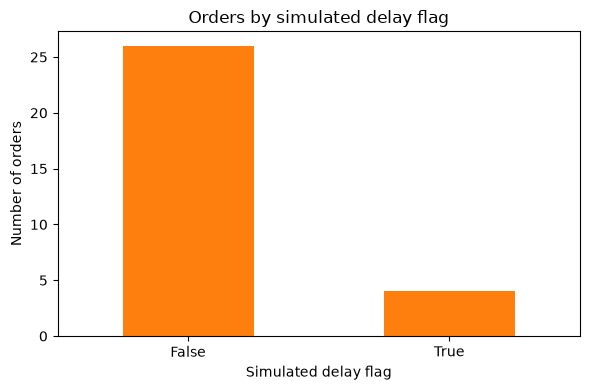

In [40]:
delay_counts = order["simulated_delay_flag"].value_counts()

ax = delay_counts.plot(kind="bar", figsize=(6, 4), color="tab:orange")
ax.set_xlabel("Simulated delay flag")
ax.set_ylabel("Number of orders")
ax.set_title("Orders by simulated delay flag")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

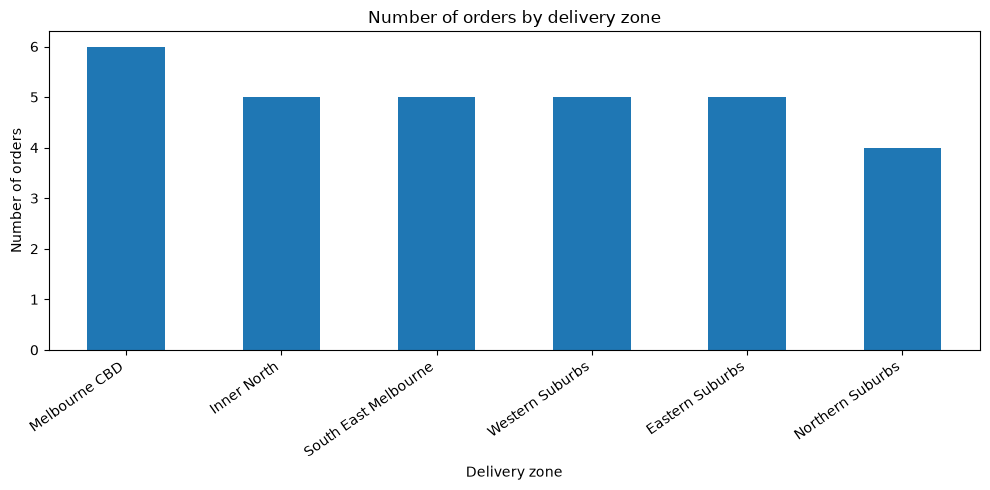

In [41]:
order_counts_by_zone = order["delivery_zone"].value_counts().sort_values(ascending=False)

ax = order_counts_by_zone.plot(kind="bar", figsize=(10, 5), color="tab:blue")
ax.set_xlabel("Delivery zone")
ax.set_ylabel("Number of orders")
ax.set_title("Number of orders by delivery zone")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

### Simulated delay flags by zone

This cross-tab checks how the generated flag is distributed in the sample. It is not a measure of actual delivery performance.

In [42]:
simulated_delay = order["simulated_delay_flag"].astype("string").str.upper().map(
    {"TRUE": True, "FALSE": False}
)
assert simulated_delay.notna().all(), "Delay flags must be TRUE or FALSE"

delay_by_zone = (
    order.assign(simulated_delay=simulated_delay)
    .groupby("delivery_zone")
    .agg(
        order_count=("order_id", "size"),
        simulated_delay_count=("simulated_delay", "sum"),
    )
)
delay_by_zone["simulated_delay_rate_pct"] = (
    100 * delay_by_zone["simulated_delay_count"] / delay_by_zone["order_count"]
)
display(delay_by_zone.sort_values("simulated_delay_rate_pct", ascending=False))

,order_count,simulated_delay_count,simulated_delay_rate_pct
delivery_zone,,,
South East Melbourne,5,2,40.000000
Northern Suburbs,4,1,25.000000
Melbourne CBD,6,1,16.666667
Eastern Suburbs,5,0,0.000000
Inner North,5,0,0.000000
Western Suburbs,5,0,0.000000


## Daily weather and order alignment

Aggregate orders to the weather data's daily grain before comparing them. Temperature and rainfall come from different station IDs, so retain both IDs and treat the measures as separate Melbourne-area proxies. This join is descriptive only.

In [43]:
temperature["date"] = pd.to_datetime(temperature[["Year", "Month", "Day"]])
rainfall["date"] = pd.to_datetime(rainfall[["Year", "Month", "Day"]])

temperature_daily = temperature[
    [
        "date",
        "Bureau of Meteorology station number",
        "Maximum temperature (Degree C)",
        "Quality",
    ]
].rename(
    columns={
        "Bureau of Meteorology station number": "temperature_station",
        "Maximum temperature (Degree C)": "maximum_temperature_c",
        "Quality": "temperature_quality",
    }
)
rainfall_daily = rainfall[
    [
        "date",
        "Bureau of Meteorology station number",
        "Rainfall amount (millimetres)",
        "Quality",
    ]
].rename(
    columns={
        "Bureau of Meteorology station number": "rainfall_station",
        "Rainfall amount (millimetres)": "rainfall_mm",
        "Quality": "rainfall_quality",
    }
)

assert temperature_daily["date"].is_unique, "Temperature must have one row per date"
assert rainfall_daily["date"].is_unique, "Rainfall must have one row per date"
weather_daily = temperature_daily.merge(
    rainfall_daily,
    on="date",
    how="outer",
    validate="one_to_one",
)

daily_orders = (
    order.assign(date=order["order_timestamp"].dt.normalize())
    .groupby("date", as_index=False)
    .agg(order_count=("order_id", "size"))
)
daily_comparison = daily_orders.merge(
    weather_daily,
    on="date",
    how="left",
    validate="one_to_one",
    indicator=True,
)

assert daily_comparison["_merge"].eq("both").all(), "Every order date must have both weather records"
assert daily_comparison["maximum_temperature_c"].notna().all(), "Matched temperature cannot be missing"
assert daily_comparison["rainfall_mm"].notna().all(), "Matched rainfall cannot be missing"
assert daily_comparison["order_count"].sum() == len(order), "Daily counts must reconcile to order rows"

print(f"Matched order dates: {len(daily_comparison)}")
print(f"Order total reconciles: {daily_comparison['order_count'].sum()} = {len(order)}")
print("Temperature station(s):", daily_comparison["temperature_station"].unique().tolist())
print("Rainfall station(s):", daily_comparison["rainfall_station"].unique().tolist())
display(daily_comparison.drop(columns="_merge").sort_values("date").reset_index(drop=True))

Matched order dates: 6
Order total reconciles: 30 = 30
Temperature station(s): ['086338']
Rainfall station(s): ['086232']


,date,order_count,temperature_station,maximum_temperature_c,temperature_quality,rainfall_station,rainfall_mm,rainfall_quality
0,2026-01-01,5,086338,20.2,Y,086232,0.0,Y
1,2026-01-02,5,086338,25.1,Y,086232,0.0,Y
2,2026-01-03,5,086338,32.4,Y,086232,0.0,Y
3,2026-01-04,5,086338,20.1,Y,086232,0.0,Y
4,2026-01-05,5,086338,20.6,Y,086232,0.0,Y
5,2026-01-06,5,086338,30.8,Y,086232,0.0,Y


## Findings and next steps

- The order sample has 30 synthetic records across six days, with exactly five orders per day. It is too small to establish real demand patterns or seasonality.
- All six order dates have temperature readings (20.1–32.4 °C) and zero recorded rainfall. With no rainfall variation in this overlap, this sample cannot test a rainfall relationship.
- The four simulated delay flags are generated labels, not observed delivery outcomes. Zone rates are based on only four to six orders per zone and should not be treated as performance comparisons.
- Temperature and rainfall use different stations (`086338` and `086232`). The files do not include a delivery-zone-to-station mapping, so do not make zone-specific weather claims.

To strengthen the next iteration, document the Bureau of Meteorology source URLs and download dates, verify both station locations and quality-flag definitions, and add a clearly documented zone mapping. Expand the synthetic order period before exploring weekday/hour patterns or comparing weather with simulated flags; record the generation seed and how flags are assigned.